# Halo model for the 21-cm signal — a BEoRN tutorial

BEoRN is the grid version of the halo-model framework for cosmic dawn and reionisation
([Schneider, Giri & Mirocha 2021](https://arxiv.org/abs/2011.12308);
[Schneider, Giri et al. 2023](https://arxiv.org/abs/2302.06626)).
Both approaches start from the **same 1D radiation profiles** around a source halo of mass $M$ at redshift $z$:
the Lyman-$\alpha$ flux $\rho_\alpha(r)$, the X-ray heating $\rho_{\rm heat}(r)$ and the ionised bubble radius $R_b$.
They differ only in the last step:

| | Grid pipeline (`beorn.painting`) | Halo model (`beorn.halo_model`) |
|---|---|---|
| haloes | catalogue from N-body / 21cmFAST / LPT+CHMF | mass function $n(M)$, bias $b(M)$ |
| fields | profiles **painted** around each halo on a 3D grid | profiles **Fourier transformed** and integrated over $n(M)$ |
| output | 3D maps → any statistic | $P(k)$ (bispectrum planned) in ~ms per redshift |

The module is generic: `HaloModel` handles **any tracer** — any field made of identical profiles around haloes —
and `HaloModel21cm` is simply a `HaloModel` with four tracers (matter, ionisation, Ly-$\alpha$ coupling, heating)
whose spectra are combined into $P_{21}$.

This notebook covers:

1. [Setup and radiation profiles](#sec1)
2. [Linear power spectrum: E&H, CAMB, CLASS](#sec2)
3. [Halo-model ingredients: $n(M)$, $b(M)$, profile windows $W_X(k|M)$](#sec3)
4. [Matter power spectrum (`HaloModelDM`)](#sec4)
5. [Any tracer: the generic `HaloModel`](#sec5)
6. [The 21-cm power spectrum (`HaloModel21cm`)](#sec6)
7. [Options: Boltzmann solver, bubble-overlap correction, accretion rate](#sec7)
8. [Parameter sensitivity](#sec8)
9. [JAX backend: gradients through the halo model](#sec9)
10. [Caveats and outlook](#sec10)

### Formalism

For fields $X, Y$ with halo windows $W_X(k|M) = 4\pi\int r^2\,\rho_X(r|M)\,j_0(kr)\,dr$ (comoving $r$):

$$P^{1h}_{XY}(k) = \int d\ln M\; n(M)\, W_X(k|M)\, W_Y(k|M),$$
$$P^{2h}_{XY}(k) = I_X(k)\, I_Y(k)\, P_{\rm lin}(k), \qquad I_X(k) = \int d\ln M\; n(M)\, b(M)\, W_X(k|M).$$

The base fields are `m` (matter overdensity, NFW haloes), `ion` ($x_{\rm HII}$, spheres of radius $R_b$),
`alpha` ($x_\alpha$) and `heat` (temperature increment $T_{\rm heat}$ in K).
Mean fields are the $k\to 0$ limits, e.g. $\bar x_{\rm HII} = \int d\ln M\, n(M)\, \tfrac{4\pi}{3}R_b^3$.

The brightness temperature
$\delta T_b = F\sqrt{1+z}\,(1-T_{\rm cmb}/T_k)(1-x_{\rm HII})\,\tfrac{x_{\rm tot}}{1+x_{\rm tot}}(1+\delta)$
is linearised around the mean fields, $\delta T_b - \overline{\delta T_b} = \sum_X A_X\, \Delta X$, with
$T_k = T_{\rm ad}(1+\delta)^{2/3} + T_{\rm heat}$ and $x_{\rm tot} = x_\alpha + x_{\rm coll}(1+\delta)$, so

$$P_{21}(k) = \sum_{X,Y} A_X A_Y\, P_{XY}(k).$$

<a id="sec1"></a>
## 1. Setup and radiation profiles

The halo model uses the same `RadiationProfiles` as the painting pipeline. By default `HaloModel21cm(param)` solves them
**in memory, without caching**: the solver takes seconds, and a halo-model scan or inference run would otherwise
write one HDF5 file per parameter set. Caching is opt-in:

```python
HaloModel21cm(param)                              # default: no cache
HaloModel21cm(param, cache_profiles=True)         # cache under ./cache (reused for identical profile parameters)
HaloModel21cm(param, cache_profiles='my_cache')   # or a path / beorn.io.Handler
HaloModel21cm(param, profiles=profiles)           # or pass profiles you already have
```

To keep the tutorial fast we use a few accretion-rate bins; the halo model picks the bin closest to `alpha` (default 0.79).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from beorn.structs import Parameters
from beorn.cosmo import get_power_spectrum
from beorn.halo_model import HaloModel, HaloModelDM, HaloModel21cm, FIELDS, FunctionTracer, halo_bias

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

param = Parameters()
param.solver.redshifts = np.arange(25, 4.75, -0.25)            # profile redshift grid, down to z = 5
param.solver.halo_mass_accretion_alpha = np.array([0.5, 0.7, 0.9])
param.solver.halo_mass_nbin = 80

t0 = time.time()
hm = HaloModel21cm(param)            # profiles solved in memory (cache_profiles=False)
profiles = hm.profiles
print(f'profiles + halo model setup: {time.time() - t0:.2f} s')
print('rho_alpha', profiles.rho_alpha.shape, ' rho_heat', profiles.rho_heat.shape,
      ' R_bubble', profiles.R_bubble.shape, '   (r, mass, alpha, z)')

profiles + halo model setup: 2.65 s
rho_alpha (1000, 79, 2, 81)  rho_heat (200, 79, 2, 81)  R_bubble (79, 2, 81)    (r, mass, alpha, z)


The profiles for a few halo masses at $z=10$ — exactly what gets painted around each halo in the grid pipeline.

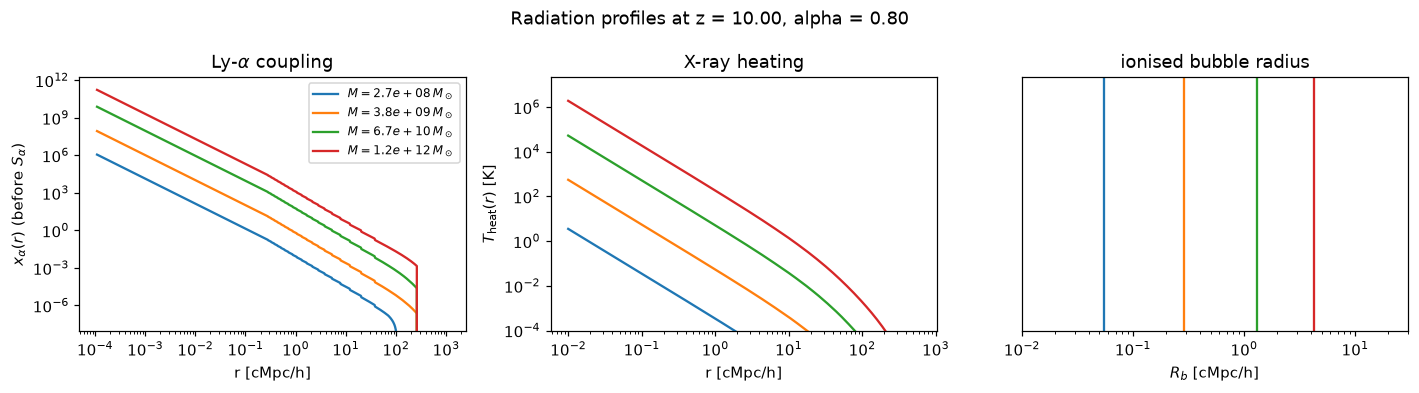

In [2]:
iz, ia = hm._z_index(10.0), hm.alpha_index
z_p = profiles.z_history[iz]
M_bins = np.sqrt(profiles.halo_mass_bins[1:, ia, iz] * profiles.halo_mass_bins[:-1, ia, iz])
# only haloes above source.halo_mass_min form stars (profiles are zero below)
active = np.where(M_bins > param.source.halo_mass_min)[0]
show = np.linspace(active[0] + 3, active[-1] - 3, 4).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for c, im in zip(['C0', 'C1', 'C2', 'C3'], show):
    lab = rf'$M={M_bins[im]:.1e}\,M_\odot$'
    x_al = 1.81e11 * profiles.rho_alpha[:, im, ia, iz] / (1 + z_p)
    axes[0].loglog(profiles.r_lyal * (1 + z_p), x_al, c, label=lab)
    axes[1].loglog(profiles.r_grid_cell, profiles.rho_heat[:, im, ia, iz], c, label=lab)
    axes[2].axvline(profiles.R_bubble[im, ia, iz], color=c, label=lab)
axes[0].set(xlabel='r [cMpc/h]', ylabel=r'$x_\alpha(r)$ (before $S_\alpha$)', title=r'Ly-$\alpha$ coupling', ylim=(1e-8, None))
axes[1].set(xlabel='r [cMpc/h]', ylabel=r'$T_{\rm heat}(r)$ [K]', title='X-ray heating', ylim=(1e-4, None))
axes[2].set(xscale='log', xlim=(1e-2, 30), yticks=[], xlabel=r'$R_b$ [cMpc/h]', title='ionised bubble radius')
axes[0].legend(fontsize=8)
fig.suptitle(f'Radiation profiles at z = {z_p:.2f}, alpha = {hm.alpha:.2f}')
fig.tight_layout()

<a id="sec2"></a>
## 2. Linear power spectrum: E&H, CAMB, CLASS

`beorn.cosmo.ps_linear` is shared by `lpt`, `mass_function` and `halo_model`:

```python
get_power_spectrum(None, param)                 # Eisenstein & Hu no-wiggle (default)
get_power_spectrum('camb', param, **ps_var)     # CAMB  — ps_var -> camb.set_params
get_power_spectrum('class', param, **ps_var)    # CLASS — ps_var -> classy.Class.set
```

Boltzmann tables are normalised to `param.cosmology.sigma_8` (unless `normalise_sigma8=False`), scaled to redshift $z$ with
BEoRN's $D(z)$, and continued beyond the solver's $k$-range with the E&H shape.

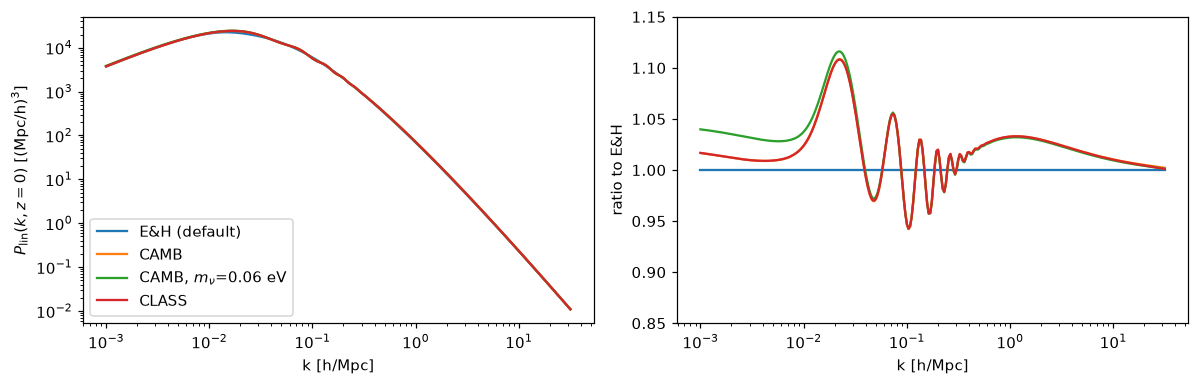

In [3]:
k = np.logspace(-3, 1.5, 300)
ps = {'E&H (default)': get_power_spectrum(None, param)}
for name, method, kw in [('CAMB', 'camb', {}), ('CAMB, $m_\\nu$=0.06 eV', 'camb', {'mnu': 0.06}), ('CLASS', 'class', {})]:
    try:
        ps[name] = get_power_spectrum(method, param, **kw)
    except ImportError as err:
        print(f'{name}: skipped ({err.msg if hasattr(err, "msg") else err})')

fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.6))
for name, p in ps.items():
    a0.loglog(k, p.P(k, z=0), label=name)
    a1.semilogx(k, p.P(k, z=0) / ps['E&H (default)'].P(k, z=0), label=name)
a0.set(xlabel='k [h/Mpc]', ylabel=r'$P_{\rm lin}(k, z=0)$ [(Mpc/h)$^3$]')
a1.set(xlabel='k [h/Mpc]', ylabel='ratio to E&H', ylim=(0.85, 1.15))
a0.legend(); fig.tight_layout()

<a id="sec3"></a>
## 3. Halo-model ingredients

`HaloModel` bundles the linear $P(k)$, the halo mass function (`beorn.mass_function.HaloMassFunction`, Sheth–Tormen by default)
and the matching peak-background-split bias. Masses are in $M_\odot$, lengths in Mpc/h.

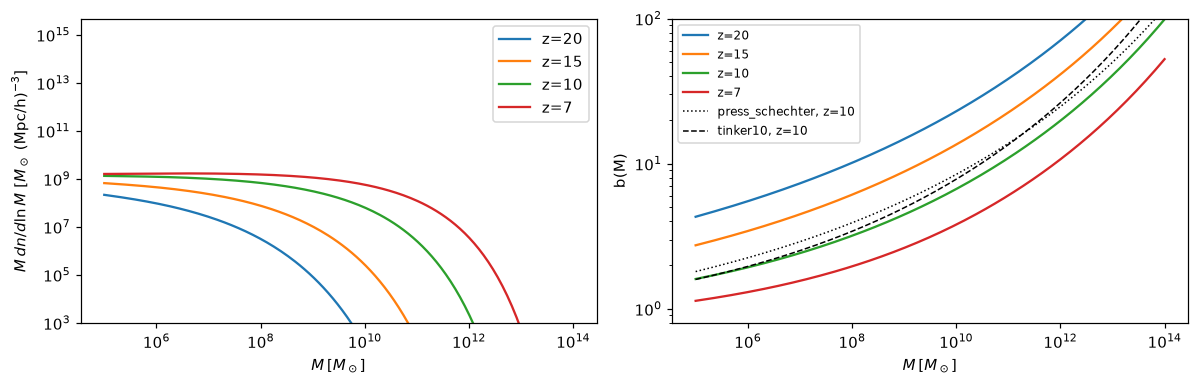

In [4]:
base = HaloModel(param)                               # ps_method=None -> E&H
M = np.logspace(5, 14, 200)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.6))
for z in [20, 15, 10, 7]:
    a0.loglog(M, M * base.dndlnm(M, z), label=f'z={z}')
    a1.loglog(M, base.bias(M, z), label=f'z={z}')
sigma = np.sqrt(base.hmf.sigma2(M, 10))
for model, ls in [('press_schechter', ':'), ('tinker10', '--')]:
    a1.loglog(M, halo_bias(sigma, model), 'k', ls=ls, lw=1, label=f'{model}, z=10')
a0.set(xlabel=r'$M\,[M_\odot]$', ylabel=r'$M\,dn/d\ln M$ [$M_\odot$ (Mpc/h)$^{-3}$]', ylim=(1e3, None))
a1.set(xlabel=r'$M\,[M_\odot]$', ylabel='b(M)', ylim=(0.8, 100))
a0.legend(); a1.legend(fontsize=8); fig.tight_layout()

The halo windows $W_X(k|M)$ of the tracers are what replaces painting; every tracer exposes them as
`hm.tracers[X].window(k, M, z)`. Tabulated profiles are transformed with a Filon-type rule
(`beorn.halo_model.profile_ft`), which stays accurate at high $k$ on BEoRN's coarse log-spaced radial grid.
Normalised by their $k\to0$ value they show the scale each field "lives" on: bubbles are compact,
X-ray heating and especially Ly-$\alpha$ extend to tens of cMpc/h.

tracers of HaloModel21cm: {'m': 'MatterTracer', 'ion': 'TopHatTracer', 'alpha': 'ProfileTracer', 'heat': 'ProfileTracer'}


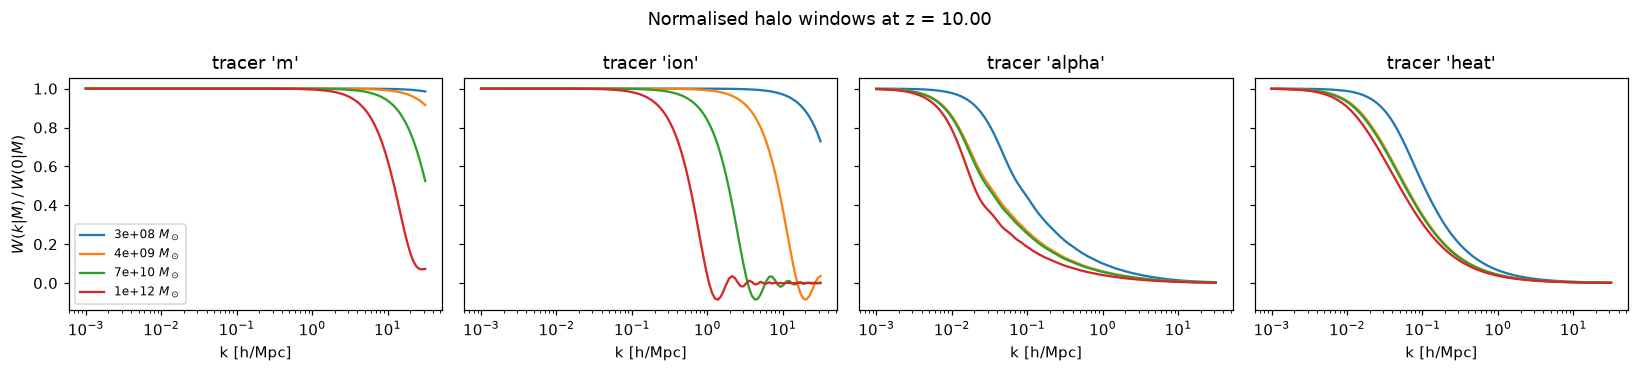

In [5]:
print('tracers of HaloModel21cm:', {name: type(t).__name__ for name, t in hm.tracers.items()})
z10 = hm.profile_redshift(10.0)
M_w, _ = hm.grid_for(z10, 'ion')                      # the profile mass bins
kw = np.logspace(-3, 1.5, 120)
k0 = np.concatenate([[1e-8], kw])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, name in zip(axes, FIELDS):
    W = hm.tracers[name].window(k0, M_w[show], z10)
    for j, im in enumerate(show):
        ax.semilogx(kw, W[1:, j] / W[0, j], label=rf'{M_w[im]:.0e} $M_\odot$')
    ax.set(title=f"tracer '{name}'", xlabel='k [h/Mpc]')
axes[0].set_ylabel(r'$W(k|M)\,/\,W(0|M)$'); axes[0].legend(fontsize=8)
fig.suptitle(f'Normalised halo windows at z = {z10:.2f}'); fig.tight_layout()

<a id="sec4"></a>
## 4. Matter power spectrum — `HaloModelDM`

`HaloModelDM` is a `HaloModel` with a single `MatterTracer`: NFW haloes with the Duffy et al. (2008) concentration.
The two-halo term includes the missing-mass correction, so $P^{2h}\to P_{\rm lin}$ on large scales.
Halo masses are in $M_\odot/h$ throughout the halo model, as for BEoRN's radiation profiles and halo catalogues.

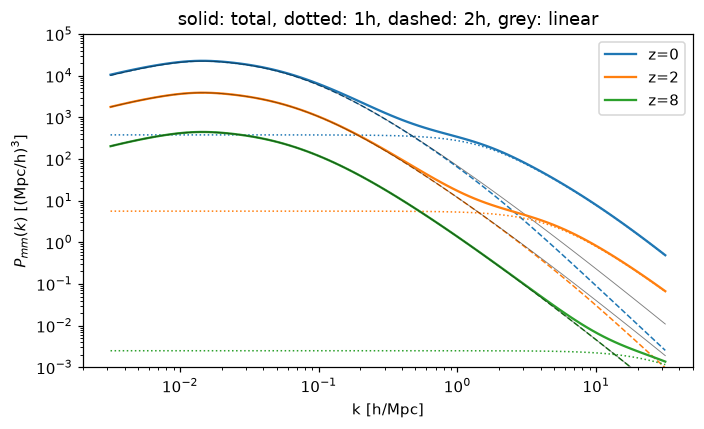

In [6]:
hdm = HaloModelDM(param)
k = np.logspace(-2.5, 1.5, 100)
fig, ax = plt.subplots(figsize=(6.5, 4))
for z, c in [(0, 'C0'), (2, 'C1'), (8, 'C2')]:
    out = hdm.power_spectrum(k, z)
    ax.loglog(k, out['P'], c, label=f'z={z}')
    ax.loglog(k, out['P_1h'], c, ls=':', lw=1)
    ax.loglog(k, out['P_2h'], c, ls='--', lw=1)
    ax.loglog(k, out['P_lin'], 'k', lw=0.6, alpha=0.5)
ax.set(xlabel='k [h/Mpc]', ylabel=r'$P_{mm}(k)$ [(Mpc/h)$^3$]', ylim=(1e-3, 1e5),
       title='solid: total, dotted: 1h, dashed: 2h, grey: linear')
ax.legend(); fig.tight_layout()

### Diagnostic: comparison with `pyhalomodel` / `hmcode`

* **[pyhalomodel](https://github.com/alexander-mead/pyhalomodel)** (Asgari, Mead & Heymans 2023) is a like-for-like check: given
  the same $\sigma(M)$, $P_{\rm lin}$, Sheth–Tormen mass function and bias, and NFW haloes with the same concentration,
  the two halo-model integrations must agree (they do to $\lesssim 0.1\%$; also a unit test).
* **[hmcode](https://github.com/alexander-mead/hmcode)** (HMcode-2020, Mead et al. 2021) is a calibrated non-linear $P(k)$:
  the plain halo model is known to under-predict the 1h–2h transition by 10–30 %.

The cell uses whichever is installed. Both pin `numpy<2`; with a numpy-2 environment install them with
`pip install --no-deps pyhalomodel hmcode` (they work fine with numpy 2; `hmcode` also needs `camb`).

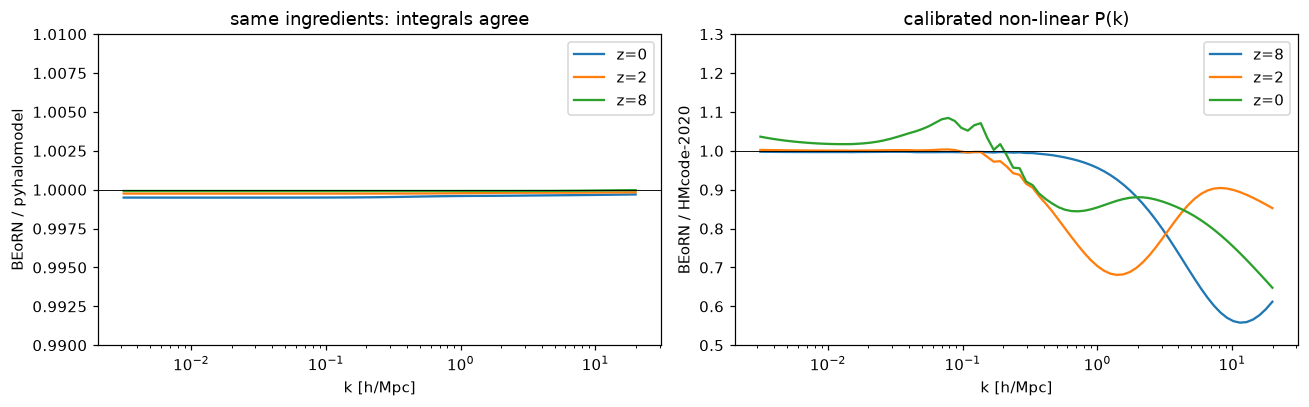

In [7]:
from beorn.halo_model import concentration_duffy08

try:
    import pyhalomodel.pyhalomodel as pyhm
except ImportError:
    pyhm = None
try:
    import hmcode
    import camb
except ImportError:
    hmcode = None

if pyhm is None and hmcode is None:
    print('For this diagnostic plot install pyhalomodel and/or hmcode:\n'
          '    pip install --no-deps pyhalomodel hmcode   (hmcode also needs camb)')
else:
    c = param.cosmology
    zs = [0.0, 2.0, 8.0]
    k = np.logspace(-2.5, 1.3, 80)
    panels = [name for name, mod in [('pyhalomodel', pyhm), ('hmcode', hmcode)] if mod is not None]
    fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 3.8), squeeze=False)
    axes = dict(zip(panels, axes[0]))

    if pyhm is not None:
        hdm_st = HaloModelDM(param)                              # Sheth-Tormen n(M), b(M); NFW + Duffy08
        M = hdm_st.M_grid                                        # M_sun/h
        for z in zs:
            sigmaM = np.sqrt(hdm_st.hmf.sigma2(M / c.h0, z))     # BEoRN's sigma(M) (its HMF works in M_sun)
            model = pyhm.model(z, c.Om, name='Sheth & Tormen (1999)', Dv=200.0, dc=hdm_st.delta_c)
            prof = pyhm.matter_profile(k, M, model.virial_radius(M), concentration_duffy08(M, z, c.h0), c.Om)
            _, _, P_ref = model.power_spectrum(k, hdm_st.plin(k, z), M, sigmaM, {'m': prof}, verbose=False)
            axes['pyhalomodel'].semilogx(k, hdm_st.power_spectrum(k, z)['P'] / P_ref['m-m'], label=f'z={z:g}')
        axes['pyhalomodel'].set(ylabel='BEoRN / pyhalomodel', ylim=(0.99, 1.01),
                                title='same ingredients: integrals agree')

    if hmcode is not None:
        h = c.h0
        kw = dict(H0=100 * h, ombh2=c.Ob * h**2, omch2=(c.Om - c.Ob) * h**2, ns=c.ns, mnu=0.0,
                  redshifts=sorted(zs, reverse=True), kmax=100.0, WantTransfer=True)
        s8 = camb.get_results(camb.set_params(As=2.1e-9, **kw)).get_sigma8_0()
        res = camb.get_results(camb.set_params(As=2.1e-9 * (c.sigma_8 / s8) ** 2, **kw))
        z_desc = sorted(zs, reverse=True)                               # hmcode wants decreasing z
        P_hmc = hmcode.power(k, np.array(z_desc), res, verbose=False)   # HMcode-2020, shape (Nz, Nk)
        hdm_camb = HaloModelDM(param, ps_method='camb')                 # same linear P(k) as HMcode
        for iz, z in enumerate(z_desc):
            axes['hmcode'].semilogx(k, hdm_camb.power_spectrum(k, z)['P'] / P_hmc[iz], label=f'z={z:g}')
        axes['hmcode'].set(ylabel='BEoRN / HMcode-2020', ylim=(0.5, 1.3),
                           title='calibrated non-linear P(k)')

    for ax in axes.values():
        ax.axhline(1, color='k', lw=0.6); ax.set_xlabel('k [h/Mpc]'); ax.legend()
    fig.tight_layout()

<a id="sec5"></a>
## 5. Any tracer: the generic `HaloModel`

A **tracer** is any field built from identical profiles around haloes. The halo model only needs its window
$W_X(k|M,z)$ (field units × volume). `HaloModel` holds any number of tracers and returns every auto- and cross-spectrum:

| tracer | use |
|---|---|
| `MatterTracer` | matter overdensity, NFW haloes (registered as `'m'` by default) |
| `ProfileTracer(name, r, rho, M_edges)` | tabulated radial profiles per mass bin (e.g. BEoRN radiation profiles) |
| `TopHatTracer(name, R, M_edges)` | uniform spheres of radius $R(M)$ (e.g. ionised bubbles) |
| `FunctionTracer(name, window, M_edges=None, bias=None)` | any function $W(k, M, z)$, optional own bias |
| subclass `Tracer` | implement `window(k, M, z)`; optionally `mass_grid`, `bias`, `two_halo_amplitude`, `mean` |

Arguments of the binned tracers may be arrays or functions of $z$. `power_spectra(k, z)` returns `P_<X>_<Y>` (+ `_1h`, `_2h`)
in absolute units and the tracer means `mean_<X>`; `power_spectrum(k, z, X, Y)` returns one pair.

**Example — a toy HI intensity-mapping tracer.** Each halo holds
$M_{\rm HI}(M) = 0.01\,M\,(M/10^{12}M_\odot)^{-0.4}\,e^{-10^{10}M_\odot/M}$, distributed like the dark matter (NFW).
Dividing by the mean gives the HI overdensity spectrum and its scale-dependent bias.

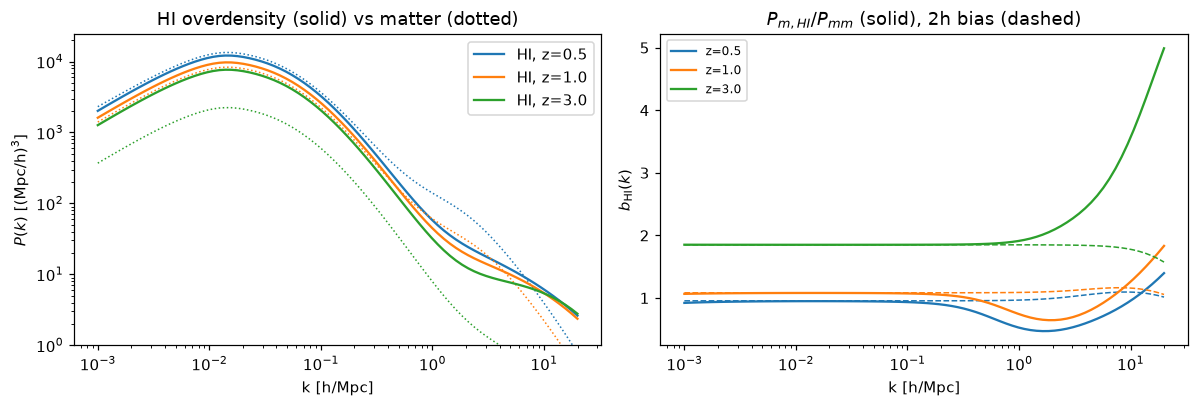

In [8]:
hg = HaloModel(param)                    # matter tracer 'm' is registered automatically
u_nfw = hg.tracers['m'].u_nfw            # reuse the NFW profile of the matter tracer

def M_HI(M):
    return 0.01 * M * (M / 1e12) ** -0.4 * np.exp(-1e10 / M)

hg.add_tracer(FunctionTracer('HI', lambda k, M, z: M_HI(M)[None, :] * u_nfw(k, M, z)))

k = np.logspace(-3, 1.3, 80)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.8))
for z, c in [(0.5, 'C0'), (1.0, 'C1'), (3.0, 'C2')]:
    o = hg.power_spectra(k, z)
    nHI = o['mean_HI']
    a0.loglog(k, o['P_HI_HI'] / nHI**2, c, label=f'HI, z={z}')
    a0.loglog(k, o['P_m_m'], c, ls=':', lw=1)
    a1.semilogx(k, o['P_m_HI'] / nHI / o['P_m_m'], c, label=f'z={z}')
    a1.semilogx(k, np.sqrt(o['P_HI_HI_2h'] / o['P_m_m_2h']) / nHI, c, ls='--', lw=1)
a0.set(xlabel='k [h/Mpc]', ylabel=r'$P(k)$ [(Mpc/h)$^3$]', title='HI overdensity (solid) vs matter (dotted)', ylim=(1, None))
a1.set(xlabel='k [h/Mpc]', ylabel=r'$b_{\rm HI}(k)$', title=r'$P_{m,HI}/P_{mm}$ (solid), 2h bias (dashed)')
a0.legend(); a1.legend(fontsize=8); fig.tight_layout()

<a id="sec6"></a>
## 6. The 21-cm power spectrum — `HaloModel21cm`

`HaloModel21cm` is a `HaloModel` that registers three more tracers from the radiation profiles —
`TopHatTracer('ion')` with radius $R_b$, `ProfileTracer('alpha')` and `ProfileTracer('heat')` — and combines the four
tracer spectra into $P_{21}$ with the linear-response coefficients $A_X$. `compute(k, z)` returns a dictionary with

* `P_21`, `P_21_1h`, `P_21_2h` [mK² (Mpc/h)³] and `Delta2_21` $=k^3P_{21}/2\pi^2$ [mK²], shape `(Nz, Nk)`;
* every tracer spectrum `P_<X>_<Y>`, `P_<X>_<Y>_1h`, `P_<X>_<Y>_2h` for $X,Y\in$ `('m', 'ion', 'alpha', 'heat')`;
* the global history `dTb`, `x_HII`, `T_k`, `x_alpha`, `x_coll`, `S_alpha`, and the response coefficients `A[X]`.

The nearest profile redshift is used for each requested $z$.

**Bubble overlap.** The `ion` tracer is a *sum* of spheres: its mean is the filling factor $Q=\int d\ln M\,n\,V_b$ and its
fluctuations keep growing once bubbles overlap. For randomly overlapping bubbles $x_{\rm HII}=1-e^{-Q}$, so
$\Delta x_{\rm HII}=(1-\bar x_{\rm HII})\,\Delta Q$: the ionisation fluctuations are suppressed by $(1-\bar x_{\rm HII})$ and
$P_{21}\to0$ as reionisation completes. This is applied by default (`bubble_correction=True`, `b_1h = b_2h = 1`);
the mean $\bar x_{\rm HII}=\min(Q,1)$ is photon-conserving, as in the painting pipeline. See section 7 for the alternatives.

In [9]:
k = np.logspace(-2, 1, 60)
z_all = profiles.z_history[(profiles.z_history <= 22)]
t0 = time.time()
out = hm.compute(k, z_all)
print(f'{len(z_all)} redshifts x {len(k)} k-modes in {time.time() - t0:.2f} s')

69 redshifts x 60 k-modes in 0.48 s


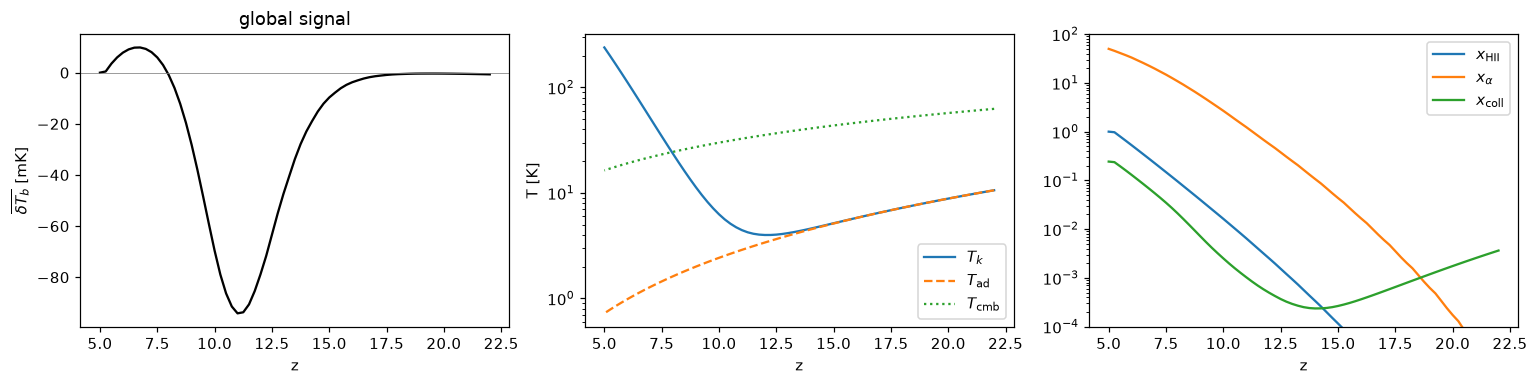

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
z = out['z']
axes[0].plot(z, out['dTb'], 'k'); axes[0].axhline(0, color='grey', lw=0.5)
axes[0].set(xlabel='z', ylabel=r'$\overline{\delta T_b}$ [mK]', title='global signal')
axes[1].semilogy(z, out['T_k'], label=r'$T_k$'); axes[1].semilogy(z, out['T_adiab'], '--', label=r'$T_{\rm ad}$')
axes[1].semilogy(z, 2.725 * (1 + z), ':', label=r'$T_{\rm cmb}$')
axes[1].set(xlabel='z', ylabel='T [K]'); axes[1].legend()
axes[2].semilogy(z, out['x_HII'], label=r'$x_{\rm HII}$'); axes[2].semilogy(z, out['x_alpha'], label=r'$x_\alpha$')
axes[2].semilogy(z, out['x_coll'], label=r'$x_{\rm coll}$'); axes[2].set(xlabel='z', ylim=(1e-4, 1e2)); axes[2].legend()
fig.tight_layout()

Power spectrum versus scale at several redshifts, and the evolution at fixed $k$ — the classic three-peak structure
(Ly-$\alpha$ coupling, X-ray heating, reionisation), with the power dropping to zero as reionisation completes
(dotted: $\bar x_{\rm HII}$, right axis).

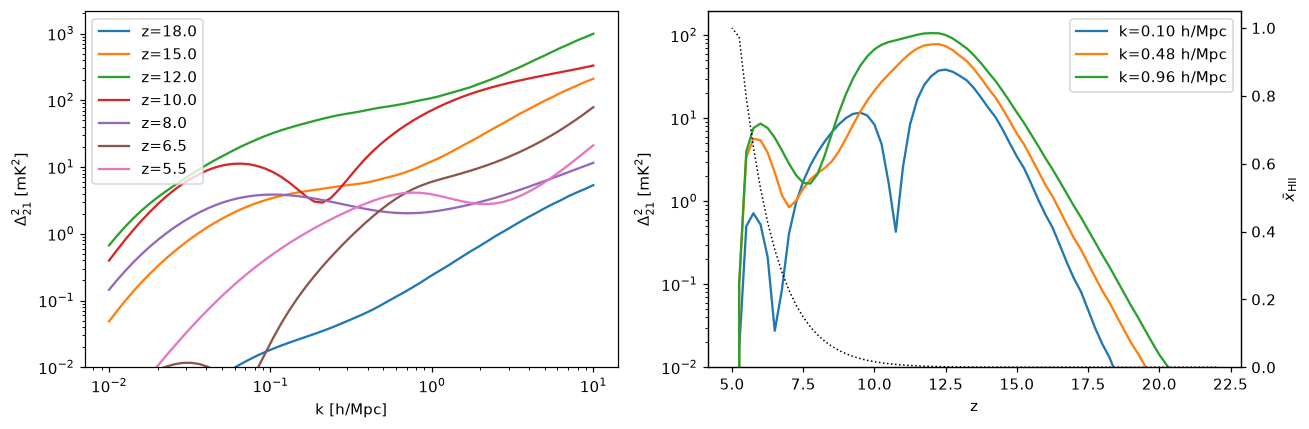

In [11]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(12, 4))
for zz in [18, 15, 12, 10, 8, 6.5, 5.5]:
    i = np.argmin(np.abs(out['z'] - zz))
    a0.loglog(k, out['Delta2_21'][i], label=f'z={out["z"][i]:.1f}')
a0.set(xlabel='k [h/Mpc]', ylabel=r'$\Delta^2_{21}$ [mK$^2$]', ylim=(1e-2, None)); a0.legend()
for kk in [0.1, 0.5, 1.0]:
    j = np.argmin(np.abs(k - kk))
    a1.semilogy(out['z'], out['Delta2_21'][:, j], label=f'k={k[j]:.2f} h/Mpc')
a1.set(xlabel='z', ylabel=r'$\Delta^2_{21}$ [mK$^2$]', ylim=(1e-2, None)); a1.legend(loc='upper right')
a1x = a1.twinx(); a1x.plot(out['z'], out['x_HII'], 'k:', lw=1); a1x.set(ylabel=r'$\bar x_{\rm HII}$', ylim=(0, 1.05))
fig.tight_layout()

### What sources the signal?

$P_{21}$ is a sum of field auto- and cross-spectra weighted by $A_X A_Y$. Splitting it up shows which process dominates
at each epoch (cross terms can be negative), and how the 1-halo and 2-halo parts compare.

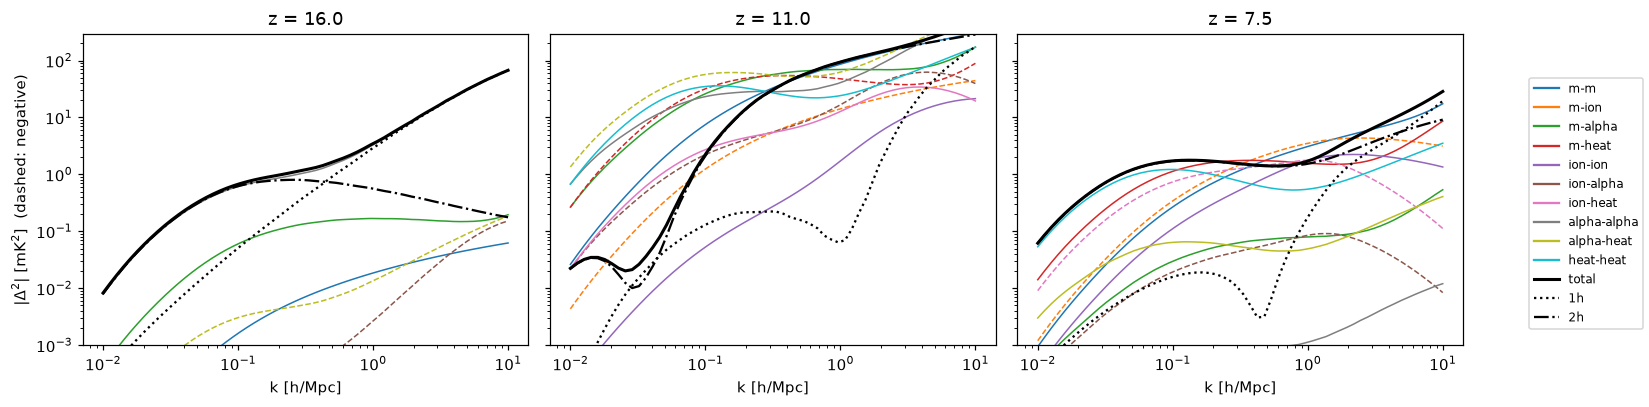

In [12]:
def contributions(out, iz):
    terms = {}
    for i, X in enumerate(FIELDS):
        for Y in FIELDS[i:]:
            fac = 1 if X == Y else 2
            terms[f'{X}-{Y}'] = fac * out['A'][X][iz] * out['A'][Y][iz] * out[f'P_{X}_{Y}'][iz]
    return terms

names = list(contributions(out, 0))
colours = dict(zip(names, plt.cm.tab10.colors))
d = k**3 / (2 * np.pi**2)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, zz in zip(axes, [16, 11, 7.5]):
    iz = np.argmin(np.abs(out['z'] - zz))
    for name, P in contributions(out, iz).items():
        Pd = P * d
        ax.loglog(k, np.where(Pd > 0, Pd, np.nan), color=colours[name], lw=1)
        ax.loglog(k, np.where(Pd < 0, -Pd, np.nan), color=colours[name], lw=1, ls='--')
    ax.loglog(k, out['Delta2_21'][iz], 'k', lw=2)
    ax.loglog(k, out['P_21_1h'][iz] * d, 'k:'); ax.loglog(k, out['P_21_2h'][iz] * d, 'k-.')
    ax.set(title=f'z = {out["z"][iz]:.1f}', xlabel='k [h/Mpc]', ylim=(1e-3, None))
axes[0].set_ylabel(r'$|\Delta^2|$ [mK$^2$]  (dashed: negative)')
handles = [plt.Line2D([], [], color=colours[n], label=n) for n in names]
handles += [plt.Line2D([], [], color='k', lw=2, label='total'), plt.Line2D([], [], color='k', ls=':', label='1h'),
            plt.Line2D([], [], color='k', ls='-.', label='2h')]
fig.legend(handles=handles, loc='center right', fontsize=8)
fig.tight_layout(rect=(0, 0, 0.9, 1))

<a id="sec7"></a>
## 7. Options

* **`ps_method` / `ps_var`** — any linear $P(k)$ from section 2; extra keywords go to the Boltzmann solver.
* **`bubble_correction`, `b_1h`, `b_2h`** — bubble overlap: the ionisation field is multiplied by $(1-\bar x_{\rm HII})^{b_{1h}}$ in the
  1h term and $(1-\bar x_{\rm HII})^{b_{2h}}$ in the 2h term. Default `True` with $b_{1h}=b_{2h}=1$ (random overlap, section 6);
  HMreio examples use $b_{1h}=1.2$, $b_{2h}=0$; `bubble_correction=False` switches it off, and then $P_{21}$ keeps growing until
  the end of reionisation.
* **`alpha`** — exponential accretion rate $\dot M = \alpha M (1+z) H(z)$ selecting the profiles.
* **`hmf_model`, `bias_model`, `window`, `delta_c`** — mass function and bias choices.

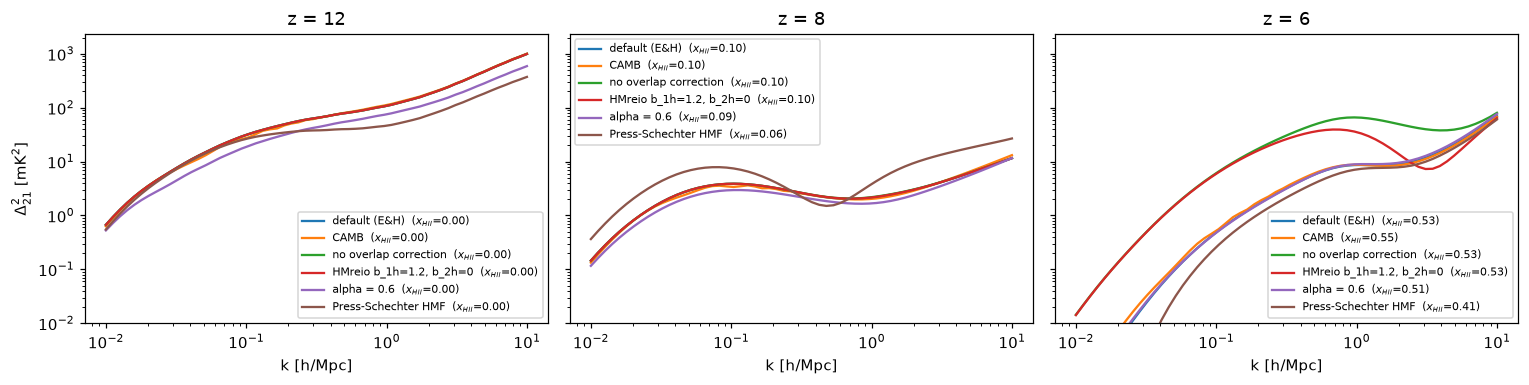

In [13]:
variants = {
    'default (E&H)': dict(),
    'CAMB': dict(ps_method='camb'),
    'no overlap correction': dict(bubble_correction=False),
    'HMreio b_1h=1.2, b_2h=0': dict(b_1h=1.2, b_2h=0.0),
    'alpha = 0.6': dict(alpha=0.6),
    'Press-Schechter HMF': dict(hmf_model='press_schechter'),
}
z_sel = [12, 8, 6]
fig, axes = plt.subplots(1, len(z_sel), figsize=(14, 3.6), sharey=True)
for name, kw in variants.items():
    try:
        o = HaloModel21cm(param, profiles, **kw).compute(k, z_sel)
    except ImportError as err:
        print(f'{name}: skipped ({err})'); continue
    for ax, i in zip(axes, range(len(z_sel))):
        ax.loglog(k, o['Delta2_21'][i], label=f'{name}  ($x_{{HII}}$={o["x_HII"][i]:.2f})')
for ax, zz in zip(axes, z_sel):
    ax.set(title=f'z = {zz}', xlabel='k [h/Mpc]', ylim=(1e-2, None)); ax.legend(fontsize=7)
axes[0].set_ylabel(r'$\Delta^2_{21}$ [mK$^2$]'); fig.tight_layout()

The overlap treatment only matters once bubbles fill a sizeable fraction of the volume. Without it the power keeps growing
as the bubble filling factor exceeds unity; with the random-overlap default it peaks around the midpoint of reionisation
and vanishes when $\bar x_{\rm HII}\to1$.

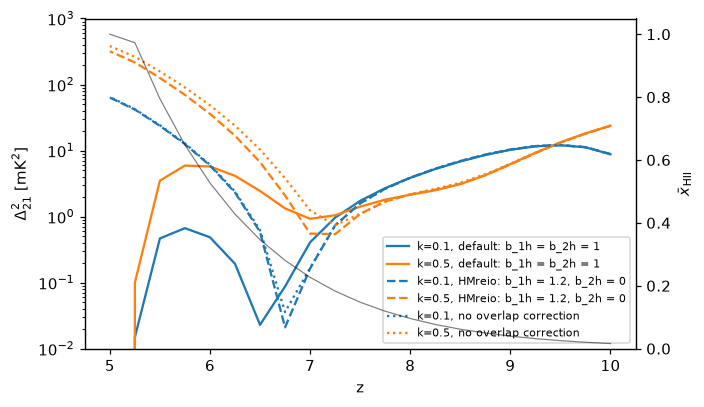

In [14]:
z_late = profiles.z_history[profiles.z_history <= 10]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, kw, ls in [('default: b_1h = b_2h = 1', dict(), '-'), ('HMreio: b_1h = 1.2, b_2h = 0', dict(b_1h=1.2, b_2h=0.0), '--'),
                     ('no overlap correction', dict(bubble_correction=False), ':')]:
    o = HaloModel21cm(param, profiles, **kw).compute(np.array([0.1, 0.5]), z_late)
    ax.semilogy(o['z'], o['Delta2_21'][:, 0], 'C0', ls=ls, label=f'k=0.1, {name}')
    ax.semilogy(o['z'], o['Delta2_21'][:, 1], 'C1', ls=ls, label=f'k=0.5, {name}')
ax.set(xlabel='z', ylabel=r'$\Delta^2_{21}$ [mK$^2$]', ylim=(1e-2, 1e3)); ax.legend(fontsize=7)
axx = ax.twinx(); axx.plot(o['z'], o['x_HII'], 'k', lw=0.8, alpha=0.5); axx.set(ylabel=r'$\bar x_{\rm HII}$', ylim=(0, 1.05))
fig.tight_layout()

<a id="sec8"></a>
## 8. Parameter sensitivity

Because the halo model is cheap, a parameter scan costs only the profile computation. `update_parameters` swaps in new
astrophysical parameters and recomputes the profiles (in memory) while keeping the linear $P(k)$, $n(M)$ and $b(M)$ —
handy with a Boltzmann solver. The cosmology must stay the same; build a new instance otherwise.
Below we vary the X-ray normalisation and the number of ionising photons per baryon.

xray_normalisation: 9.2 s for 3 models


Nion: 9.2 s for 3 models


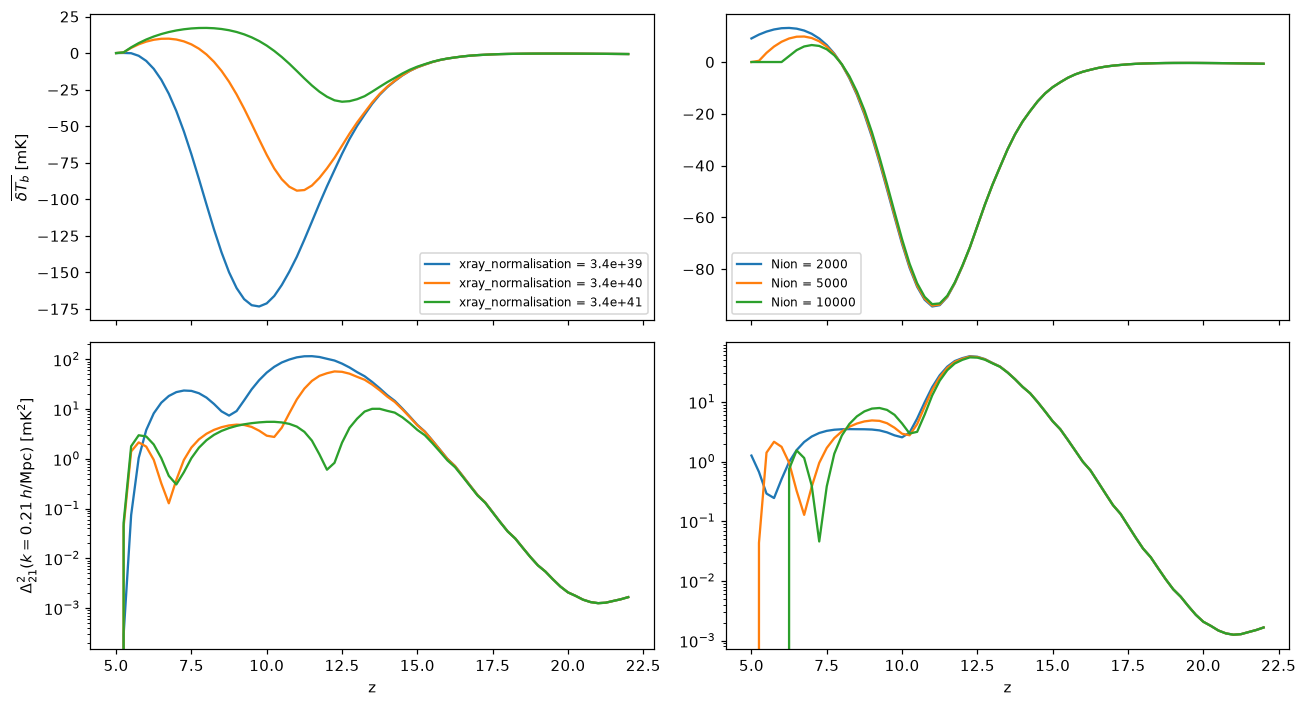

In [15]:
import copy

hm_scan = HaloModel21cm(param, profiles=profiles)

def run(**source):
    p = copy.deepcopy(param)
    for key, val in source.items():
        setattr(p.source, key, val)
    hm_scan.update_parameters(p)          # new profiles, same P(k) / n(M) / b(M); nothing written to disk
    return hm_scan.compute(k, z_all)

j = np.argmin(np.abs(k - 0.2))
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for col, (key, values) in enumerate([('xray_normalisation', [3.4e39, 3.4e40, 3.4e41]), ('Nion', [2000, 5000, 10000])]):
    t0 = time.time()
    for val in values:
        o = run(**{key: val})
        axes[0, col].plot(o['z'], o['dTb'], label=f'{key} = {val:g}')
        axes[1, col].semilogy(o['z'], o['Delta2_21'][:, j])
    print(f'{key}: {time.time() - t0:.1f} s for {len(values)} models')
    axes[0, col].legend(fontsize=8); axes[1, col].set_xlabel('z')
axes[0, 0].set_ylabel(r'$\overline{\delta T_b}$ [mK]')
axes[1, 0].set_ylabel(rf'$\Delta^2_{{21}}(k={k[j]:.2f}\,h/{{\rm Mpc}})$ [mK$^2$]')
fig.tight_layout()

<a id="sec9"></a>
## 9. JAX backend: gradients through the halo model

The profile transforms and the 1h/2h integrators run in numpy, JAX or torch (`backend=...`), and the transform is a
fixed linear map of the profile values. With JAX we can therefore differentiate halo-model spectra with respect to
the profiles — the building block for differentiable inference (issue #42). Here: the logarithmic derivative of the
one-halo ionisation and heating spectra with respect to a rescaling of the bubble radius, $R_b \to sR_b$, and of the
heating profile, $T_{\rm heat} \to aT_{\rm heat}$. On large scales $P^{1h}_{\rm ion}\propto R_b^6$ and $P^{1h}_{\rm heat}\propto a^2$.

On Apple Silicon JAX runs on the CPU (`jax-metal` has no float64); on a CUDA machine the same code runs on the GPU.

JAX 0.10.2 devices: [CpuDevice(id=0)]


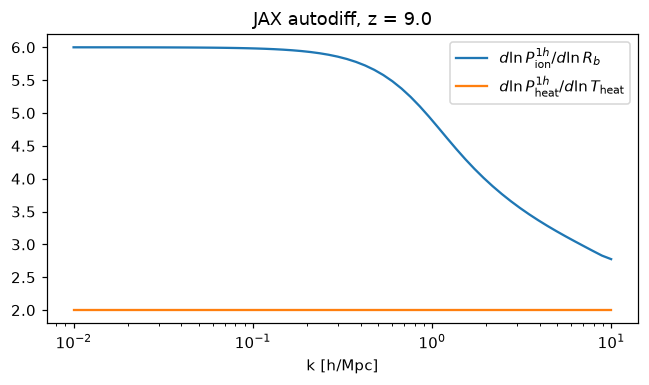

In [16]:
try:
    import jax
    jax.config.update('jax_enable_x64', True)
except ImportError:
    jax = None
    print('JAX not installed: pip install "beorn[jax]"')

if jax is not None:
    from beorn.halo_model import tophat_ft, profile_ft
    print('JAX', jax.__version__, 'devices:', jax.devices())

    hmj = HaloModel21cm(param, profiles=profiles, backend='jax')
    kj = np.logspace(-2, 1, 60)
    zj = hmj.profile_redshift(9.0)
    M_j, dlnM_j = hmj.grid_for(zj, 'ion')
    w_j = hmj.dndlnm(M_j, zj) * dlnM_j                    # quadrature weights n(M) dlnM
    R_b = hmj._R_bubble(zj)                               # bubble radius per mass bin
    rho_heat = hmj._T_heat_profile(zj)                    # (Nr, NM) heating profiles

    def P1h_ion(s):
        return hmj.one_halo(w_j, tophat_ft(kj, s * R_b, backend='jax'))

    def P1h_heat(a):
        return hmj.one_halo(w_j, profile_ft(kj, profiles.r_grid_cell, a * rho_heat, backend='jax'))

    dlnP_ion = jax.jit(jax.jacfwd(P1h_ion))(1.0) / P1h_ion(1.0)
    dlnP_heat = jax.jit(jax.jacfwd(P1h_heat))(1.0) / P1h_heat(1.0)

    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.semilogx(kj, dlnP_ion, label=r'$d\ln P^{1h}_{\rm ion}/d\ln R_b$')
    ax.semilogx(kj, dlnP_heat, label=r'$d\ln P^{1h}_{\rm heat}/d\ln T_{\rm heat}$')
    ax.set(xlabel='k [h/Mpc]', title=f'JAX autodiff, z = {zj:.1f}'); ax.legend(); fig.tight_layout()

<a id="sec10"></a>
## 10. Caveats and outlook

Approximations of the current implementation (issue [#38](https://github.com/cosmic-reionization/BEoRN/issues/38)):

* ionised bubbles use the **halo bias** (no excursion-set bubble bias yet) and overlap is treated statistically through the
  $(1-\bar x_{\rm HII})$ suppression — the grid pipeline instead redistributes excess photons explicitly;
* $S_\alpha$ and the temperature dependence of $x_{\rm coll}$ are evaluated at the mean fields;
* a single accretion-rate bin is used per run (`alpha`), and the nearest profile redshift;
* close to bright sources $x_\alpha \gg 1$ and $T_{\rm heat} \gg T_{\rm cmb}$, where $\delta T_b$ saturates; the linear response
  does not, so the **1-halo term at high $k$** ($k \gtrsim 1\,h$/Mpc) is overestimated, especially during Ly-$\alpha$ coupling;
* consistency with **HMreio** (Schneider, Giri et al. 2023), the halo-model code this framework grew out of, at matched
  parameters and with the overlap correction switched off in both: $n(M)$, $b(M)$, $P_{\rm lin}$ within 3 % (HMreio's growth-factor quadrature), global history ($\delta T_b$, $T_k$,
  $x_\alpha$) within a few %, $x_{\rm HII}$ within 5–25 % at $z<12$ and $\Delta^2_{21}$ within 10–40 % for $z\approx 9$–19 at
  $k\lesssim 1\,h$/Mpc; larger differences during reionisation, where HMreio uses an excursion-set bubble bias;
* the linearisation of $\delta T_b$ is least accurate when fluctuations are large (deep in the absorption trough or late in reionisation).

Next steps: a dedicated bubble tracer with excursion-set bubble bias (via the `Tracer.bias` hook), validation of $P_{21}$ against painted boxes with the same parameters, and the halo-model **bispectrum**
(`HaloModel.bispectrum`, Phase B).